# Half-shifted Apéry limits

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

These are limit identifications; finite-depth deltas do not assert irrationality. The big Apéry target has limited independent precision.

**Run status:**

- Big Apéry: The independent Barnes target has only 60 digits; insufficient to measure a depth-500 delta.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from ramanujantools.cmf.meijer_g import MeijerG

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, x2, y0, y1 = sp.symbols("x0 x1 x2 y0 y1")
half = sp.Rational(1, 2)


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Cohen–Zudilin (2025): Tiny Apéry: limit $R^2$

[arXiv:2501.10090](https://arxiv.org/abs/2501.10090).

**CMF:** ${}_2F_1(-1)$, dual · **Start:** $(\tfrac12,\tfrac12;1)$ ·
**Direction:** $(1,1;2)$ · readout $r_N=4s_0/(s_0+4s_1)$.
At the start, $U_j=\theta^j{}_2F_1(\tfrac12,\tfrac12;1;z)|_{z=-1}$ satisfy
$R^2=4U_0/(U_0+4U_1)$.

In [5]:
cmf = pFq(2, 1, -1).dual()
start = {x0: half, x1: half, y0: 1}
trajectory = {x0: 1, x1: 1, y0: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [4 * W[0, 0] / (W[0, 0] + 4 * W[1, 0]) for W in walks]
target = lambda: ((arb(1) / 4).gamma() / (arb(3) / 4).gamma()) ** 2

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Tiny Apéry, $R^2$'] = (DEPTHS, deltas)
accuracy['Tiny Apéry, $R^2$'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.041296726808


## 2. Cohen–Zudilin (2025): Small Apéry: limit $R^4$

[arXiv:2501.10090](https://arxiv.org/abs/2501.10090).

**CMF:** ${}_3F_2(1)$, dual · **Start:** $(\tfrac32,\tfrac32,\tfrac32;3,3)$ ·
**Direction:** $(1,1,1;2,2)$ · readout $r_N=16(9s_0+5s_1)/(2s_0+s_1)$.
At the start, $V_j=\theta^j{}_3F_2(\tfrac32,\tfrac32,\tfrac32;3,3;z)|_{z=1}$
satisfy $R^4=16(9V_0+5V_1)/(2V_0+V_1)$.

In [7]:
cmf = pFq(3, 2, 1).dual()
start = {x0: 3 * half, x1: 3 * half, x2: 3 * half, y0: 3, y1: 3}
trajectory = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [16 * (9 * W[0, 0] + 5 * W[1, 0]) / (2 * W[0, 0] + W[1, 0]) for W in walks]
target = lambda: ((arb(1) / 4).gamma() / (arb(3) / 4).gamma()) ** 4

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Small Apéry, $R^4$'] = (DEPTHS, deltas)
accuracy['Small Apéry, $R^4$'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.229101469679


## 3. Cohen–Zudilin (2025): Big Apéry: limit $-3\eta_+/\omega_+$

[arXiv:2501.10090](https://arxiv.org/abs/2501.10090).

**CMF:** Meijer $G$, $G^{4,2}_{4,4}(1)$, dual ·
**Start:** $(\tfrac12,\tfrac12,\tfrac12,\tfrac12;0,0,0,0)$ ·
**Direction:** $(-1,-1,1,1;0,0,0,0)$ · readout $r_N=-768(s_1+2s_2)/s_0$,
with $\omega_+,\eta_+$ normalized as in Cohen–Zudilin, Section 3.

In [ ]:
cmf = MeijerG(4, 2, 4, 4, 1).dual()
axes = sp.symbols('a0:4') + sp.symbols('b0:4')
start = dict(zip(axes, [half] * 4 + [0] * 4))
trajectory = dict(zip(axes, [-1, -1, 1, 1] + [0] * 4))
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [-768 * (W[1, 0] + 2 * W[2, 0]) / W[0, 0] for W in walks]
print('Depth-500 delta unavailable: the independent Barnes target has only 60 digits.')

Not computed: The independent Barnes target has only 60 digits; insufficient to measure a depth-500 delta.


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

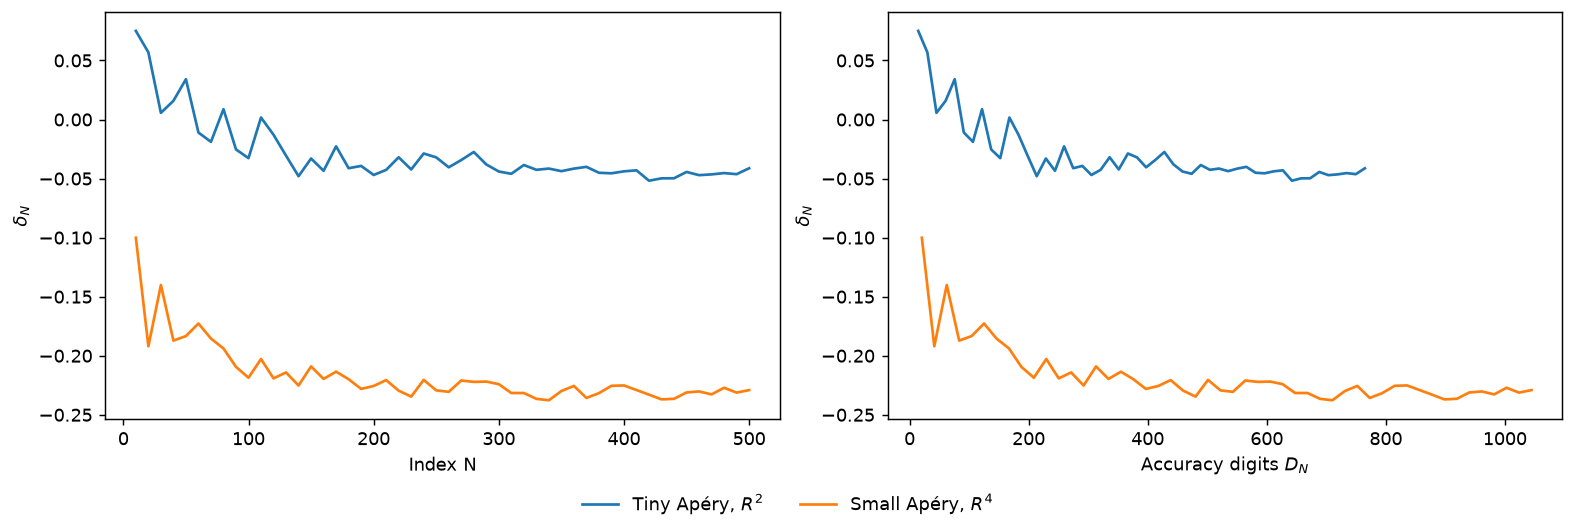

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [13]:
bounds = {
    'Tiny Apéry, $R^2$': 'Limit identity (2025)',
    'Small Apéry, $R^4$': 'Limit identity (2025)',
    'Big Apéry': 'Limit identity (2025)',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Tiny Apéry, $R^2$ | Limit identity (2025) | -0.041296726808 (N = 500) |
| Small Apéry, $R^4$ | Limit identity (2025) | -0.229101469679 (N = 500) |
| Big Apéry | Limit identity (2025) | Not computed |